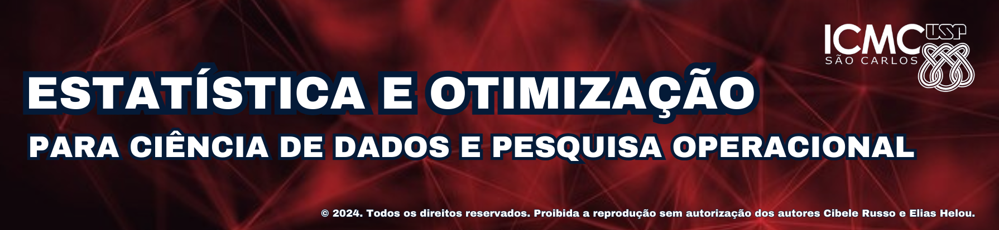

<h1 style = 'text-align: center;'>Algoritmo de Gradiente Projetado</h1>

por **Elias Helou**

**ICMC/USP - São Carlos SP**

<h2>Conteúdo do Vídeo</h2>

1. Projeções

2. Gradiente Projetado

## 1. Projeções

Uma projeção é uma operação que leva para dentro de um conjunto de uma forma específica.

Seja $\mathbb X\subset \mathbb R^n$, então, para $\bm x \in \mathbb R^n$, definimos a projeção $\mathcal P_{\mathbb X}( \bm x )$ de $\bm x$ sobre $\mathbb X$ como o ponto mais próximo de $\bm x$ no conjunto $\mathbb X$
$$
\mathcal P_{\mathbb X}( \bm x ) = \argmin_{\bm y \in \mathbb X}\ \| \bm x - \bm y \|_2.
$$

Observe que se $\bm x \in \mathbb X$, então
$$
\mathcal P_{\mathbb X}( \bm x ) = \bm x.
$$

In [1]:
import plotly
import plotly.graph_objects as go
import numpy as np
from IPython.display import display, HTML

plotly.offline.init_notebook_mode()
display(HTML(
    '<script type="text/javascript" async src="https://cdnjs.cloudflare.com/ajax/libs/mathjax/2.7.1/MathJax.js?config=TeX-MML-AM_SVG"></script>'
))

theta = np.linspace( 0.0, 2 * np.pi, 200 )

trace = go.Scatter(
    mode = 'lines',
    x = np.cos( theta ),
    y = np.sin( theta ),
    line = {
        'width': 1.5,
        'color': 'rgb( 255, 153, 28 )'
    },
    hoverinfo = None,
    text = None,
    name = '',
    fill = 'toself'
 )

o_x = -1.3
o_y = -1.3
alpha = ( o_x ** 2 + o_y ** 2 ) ** 0.5
p_x = o_x / alpha
p_y = o_y / alpha

p_trace = go.Scatter(
    x = [ o_x, p_x ], y = [ o_y, p_y ], mode = 'markers+lines',
    line = {
        'width': 1.5,
        'color': 'rgb( 0, 0, 0 )',
        'dash': 'dot'
    },
    marker = {
        'color': 'blue'
    },
    name = '',
    hoverinfo = 'skip', hovertemplate = None
)
p_trace.text = [ '' ] * 3

fig = go.FigureWidget(
    data = [ trace, p_trace ],
    layout = {
        'width'        : 500,
        'height'       : 500,
        'xaxis'        : dict(
            showgrid = False,
            zeroline = False,
            showticklabels = False,
            range = ( -1.9, 1.3 )
            ),
        'yaxis'        : dict(
            showgrid = False,
            zeroline = False,
            showticklabels = False,
            range = ( -1.9, 1.1 ),
            scaleanchor = 'x',
            scaleratio = 1.0
            ),
        'plot_bgcolor' : 'rgb( 255, 255, 255 )',
        'showlegend': False,
        'margin': dict( b = 0, l = 0, r = 0, t = 0 )
        }
)

fig.add_annotation(
    x = 0.5, y = 0.5, text = r'$\LARGE\mathbb X$', showarrow = False
)
fig.add_annotation(
    x = o_x, y = o_y, text = r'$\Large\boldsymbol x$', showarrow = False, xanchor = 'right', yanchor = 'bottom', xshift = -5
)
fig.add_annotation(
    x = p_x, y = p_y, text = r'$\Large\mathcal P_{\mathbb X}( \boldsymbol x )$', showarrow = False, xanchor = 'left', yanchor = 'bottom', xshift = 5
)

fig.show()

FigureWidget({
    'data': [{'fill': 'toself',
              'line': {'color': 'rgb( 255, 153, 28 )', 'width': 1.5},
              'mode': 'lines',
              'name': '',
              'type': 'scatter',
              'uid': 'ea56f0df-81f0-48e9-8035-d2b3e8f70977',
              'x': {'bdata': ('AAAAAAAA8D8uGrPB6vvvP6bDhxGs7+' ... 'Gs7+8/Lhqzwer77z8AAAAAAADwPw=='),
                    'dtype': 'f8'},
              'y': {'bdata': ('AAAAAAAAAAB13qTBwCmgPw9urs6wJ7' ... '6wJ7C/TN6kwcApoL8HXBQzJqaxvA=='),
                    'dtype': 'f8'}},
             {'hoverinfo': 'skip',
              'line': {'color': 'rgb( 0, 0, 0 )', 'dash': 'dot', 'width': 1.5},
              'marker': {'color': 'blue'},
              'mode': 'markers+lines',
              'name': '',
              'text': [, , ],
              'type': 'scatter',
              'uid': '52d74b1f-e1d2-463f-b2ee-bbc35d2c9c2b',
              'x': [-1.3, -0.7071067811865475],
              'y': [-1.3, -0.7071067811865475]}],
    'layou

### 1.1. Existência da Projeção

As seguintes condições garantem que a projeção sobre $\mathbb X$ sempre existe:

- $\mathbb X$ não é vazio

- $\mathbb X$ é fechado (seu complementar é aberto)



In [2]:
fig.data[ 0 ].line.dash = 'dot'

### 1.2. Unicidade da Projeção

Se as condições acima forem satisfeitas, a hipótese abaixo garante a unicidade da projeção

- $\mathbb X$ é convexo

Mas se $\mathbb X$ não for convexo, pode haver mais de um minimizador da distância.


In [3]:
delta = 0.8

trace_a = go.Scatter(
    mode = 'lines',
    x = np.cos( theta ) + delta,
    y = np.sin( theta ),
    line = {
        'width': 1.5,
        'color': 'rgb( 255, 153, 28 )'
    },
    hoverinfo = None,
    text = None,
    name = '',
    fill = 'toself'
 )

trace_b = go.Scatter(
    mode = 'lines',
    x = np.cos( theta ) - delta,
    y = np.sin( theta ),
    line = {
        'width': 1.5,
        'color': 'rgb( 255, 153, 28 )'
    },
    hoverinfo = None,
    text = None,
    name = '',
    fill = 'toself'
 )

o_x_n = 0
o_y_n = -1.3
alpha = ( ( o_x_n - delta ) ** 2 + o_y_n ** 2 ) ** 0.5
p_x_n = ( o_x_n - delta ) / alpha
p_y_n = o_y_n / alpha

p_trace_n = go.Scatter(
    x = [ o_x_n, delta + p_x_n, None, o_x_n, -delta - p_x_n ],
    y = [ o_y_n, p_y_n, None, o_y_n, p_y_n ], mode = 'markers+lines',
    line = {
        'width': 1.5,
        'color': 'rgb( 0, 0, 0 )',
        'dash': 'dot'
    },
    marker = {
        'color': 'blue'
    },
    name = '',
    hoverinfo = 'skip', hovertemplate = None
)
p_trace.text = [ '' ] * 3

r = ( ( delta + p_x_n - o_x_n ) ** 2 + ( p_y_n - o_y_n ) ** 2 ) ** 0.5
p_trace_circle = go.Scatter(
    x = o_x_n + r * np.cos( theta ),
    y = o_y_n + r * np.sin( theta ),
    line = { 'width': 0, 'dash': 'dot', 'color': 'black' },
    name = '',
    hoverinfo = 'skip', hovertemplate = None
)

fig_2 = go.FigureWidget(
    data = [ p_trace_circle, trace_a, trace_b, p_trace_n ],
    layout = {
        'width'        : 800,
        'xaxis'        : dict(
            showgrid = False,
            zeroline = False,
            showticklabels = False,
            range = ( -2, 2 )
            ),
        'yaxis'        : dict(
            showgrid = False,
            zeroline = False,
            showticklabels = False,
            range = ( -1.9, 1.2 ),
            scaleanchor = 'x',
            scaleratio = 1.0
            ),
        'plot_bgcolor' : 'rgb( 255, 255, 255 )',
        'showlegend': False,
        'margin': dict( b = 0, l = 0, r = 0, t = 0 )
        }
)

fig_2.add_annotation(
    x = 0.5 + delta, y = 0.5, text = r'$\LARGE\mathbb X$', showarrow = False
)
fig_2.add_annotation(
    x = o_x_n, y = o_y_n, text = r'$\Large\boldsymbol x$', showarrow = False, xanchor = 'right', yanchor = 'top', xshift = -5
)
fig_2.add_annotation(
    x = delta + p_x_n, y = p_y_n, text = r'$\Large\mathcal P_{\mathbb X}( \boldsymbol x )$', showarrow = False, xanchor = 'left', yanchor = 'bottom', xshift = 5
)
fig_2.add_annotation(
    x = -delta - p_x_n, y = p_y_n, text = r'$\Large\mathcal P_{\mathbb X}( \boldsymbol x )$', showarrow = False, xanchor = 'right', yanchor = 'bottom', xshift = -5
)

fig_2.show()

FigureWidget({
    'data': [{'hoverinfo': 'skip',
              'line': {'color': 'black', 'dash': 'dot', 'width': 0},
              'name': '',
              'type': 'scatter',
              'uid': '1f48918c-0ae5-4e00-9fdd-5ecb698b2916',
              'x': {'bdata': ('ojetmIvY4D8KfFJYZdbgP/TyrCPzz+' ... 'Pzz+A/CnxSWGXW4D+iN62Yi9jgPw=='),
                    'dtype': 'f8'},
              'y': {'bdata': ('zczMzMzM9L+4hwnHuoj0vwJoKCC6RP' ... 'nfVPW/4hGQ0t4Q9b/OzMzMzMz0vw=='),
                    'dtype': 'f8'}},
             {'fill': 'toself',
              'line': {'color': 'rgb( 255, 153, 28 )', 'width': 1.5},
              'mode': 'lines',
              'name': '',
              'type': 'scatter',
              'uid': '8f879c44-beb0-4a74-b54b-2aa05eb2105c',
              'x': {'bdata': ('zczMzMzM/D/kWaYtwsr8P6CukNWixP' ... 'WixPw/5FmmLcLK/D/NzMzMzMz8Pw=='),
                    'dtype': 'f8'},
              'y': {'bdata': ('AAAAAAAAAAB13qTBwCmgPw9urs6wJ7' ... '6wJ7C/TN6kwcApoL8HXBQzJqa

In [4]:
fig_2.data[ 0 ].line.width = 0.5

### 1.3. Projeção como Operador Proximal

Consideremos a função indicadora $\delta_{\mathbb X}$ de um conjunto convexo fechado não-vazio $\mathbb X \in \mathbb R^n$:
$$
\delta_{\mathbb X}( \bm x ) = \begin{cases}0&\bm x \in \mathbb X\\\infty & \bm x\notin\mathbb X.\end{cases}
$$

Então a projeção $\mathcal P_{\mathbb X}( \bm x )$ de $\bm x$ sobre $\mathbb X$ coincide com o proximal $\text{prox}_{\delta_{\mathbb X}}( \bm x )$ de $\delta_{\mathbb X}$ calculado em $\bm x$:
$$
    \mathcal P_{\mathbb X}( \bm x ) = \text{prox}_{\delta_{\mathbb X}}( \bm x ) = \argmin_{\bm y \in \mathbb R^n}\quad\frac12\| \bm y - \bm x \|_2^2 + \delta_{\mathbb X}( \bm y ).
$$

### 1.4. Conjuntos de Nível

Por exemplo, suponha que $g : \mathbb R^n \to \mathbb R$ seja convexa (consequentemente, contínua), então um conjunto da forma
$$
    \text{lev}_g := \{ \bm x : g( \bm x ) \le 0 \}
$$
é sempre convexo e fechado.

Observações:

- Desigualdade do tipo menor ou igual ($\le$)
    - A direção é fundamental para convexidade
    - A igualdade é fundamental para fechamento

- O conjunto $\text{lev}_g$ pode ser vazio!

- Pode ser computacionalmente difícil calcular a projeção

## 2. Gradiente Projetado

Considere o problema de otimização convexa
$$
    \begin{align*}
        \min        \quad& f( \bm x )\\
        \text{s.a:} \quad& \bm x \in \mathbb X,
    \end{align*}
$$
onde

- $f : \mathbb R^n \to \mathbb R$ é convexa e suave, ou seja
$$
    \| \nabla f( \bm x ) - \nabla f( \bm y ) \|_2 \le L_f\| \bm x - \bm y \|_2
$$

- $\mathbb X$ é não-vazio, fechado e convexo

- a projeção $\mathcal P_{\mathbb X}( \bm x )$ é facilmente computável



### 2.1. Algoritmos para Problemas com Restrição

Uma vez que a projeção é um caso particular do operador proximal, métodos como o gradiente proximal se tornam aplicáveis, sob a forma
$$
    \bm x^{( k + 1 )} = \mathcal P_{\mathbb X}\bigl( \bm x^{ ( k ) } - \lambda \nabla f( \bm x^{ ( k ) } ) \bigr).
$$
Ou, ainda mais interessante, a versão acelerada
$$\def\vect{\bm}
\begin{align*}
    \vect y^{( k )} &{}= \mathcal P_{\mathbb X}\bigl( \vect x^{( k )} - \lambda \nabla f( \vect x^{( k )} ) \bigr)\\
    t_{k + 1} &{}= \frac{1 + \sqrt{1 + 4t_k^2}}2\\
    \vect x^{( k + 1 )} &{}= \vect y^{( k )} + \frac{t_k - 1}{t_{k + 1}}( \vect y^{( k )} - \vect y^{( k - 1 )} ).
\end{align*}
$$

### 2.2. Exemplo

Consideremos, por exemplo, o problema
$$
    \begin{align*}
        \min        \quad& \frac 12\bm x^T Q \bm x + \bm d^T\bm x\\
        \text{s.a:} \quad& \| \bm x \|_2 \le 1,
    \end{align*}
$$
com $Q \in \mathbb R^{2\times2}$ simétrica semi-definida positiva e $\bm d\in\mathbb R^2$ gerados aleatoriamente.

In [5]:
np.random.seed( 100 )

A = np.random.normal( size = ( 2, 2 ) )
d = np.random.normal( size = ( 2, ) )
Q = A.T @ A

def f( x ):
    return 0.5 * ( x.T @ Q @ x ) + d @ x

x_min = -1.5
x_max = -x_min

X = np.linspace( x_min, x_max, 200 )
z = np.empty( ( len( X ), len( X ) ) )
for j, x in enumerate( X ):
    for i, y in enumerate( X ):
        z[ i, j ] = f( np.array( ( x, y ) ) )

img = go.Contour(
    x = X,
    y = X,
    z = z,
    ncontours = 100,
    line = { 'width': 0 },
    colorscale = 'gray_r',
    name = 'f( x, y )'
)

c_trace = go.Scatter(
    mode = 'lines',
    x = np.cos( theta ),
    y = np.sin( theta ),
    line = {
        'width': 1.5,
        'color': 'rgb( 255, 153, 28 )'
    },
    hoverinfo = 'skip',
    text = None,
    name = '',
    fill = 'toself'
 )

s_trace = go.Scatter(
    x = [],
    y = [],
    mode = 'markers',
    hoverinfo = 'text'
)
s_gtrace = go.Scatter(
    x = [],
    y = [],
    mode = 'markers',
    hoverinfo = 'text'
)
s_ftrace = go.Scatter(
    x = [],
    y = [],
    mode = 'markers',
    hoverinfo = 'text',
    marker = { 'color': 'rgba( 0, 0, 255, 0.75 )' }
)

fig = go.FigureWidget(
    data = [ img, c_trace, s_trace, s_gtrace, s_ftrace ],
    layout = {
        'width'        : 550,
        'height'       : 550,
        'xaxis'        : dict(
            showgrid = False,
            zeroline = False,
            showticklabels = False,
            range = ( x_min, x_max )
            ),
        'yaxis'        : dict(
            showgrid = False,
            zeroline = False,
            showticklabels = False,
            range = ( x_min, x_max ),
            scaleanchor = 'x',
            scaleratio = 1.0
            ),
        'plot_bgcolor' : 'rgb( 255, 255, 255 )',
        'showlegend': False,
        'margin': dict( b = 0, l = 0, r = 0, t = 0 )
        }
)

fig.show()


FigureWidget({
    'data': [{'colorscale': [[0.0, 'rgb(254, 254, 253)'], [0.09090909090909091,
                             'rgb(224, 224, 223)'], [0.18181818181818182, 'rgb(197,
                             197, 195)'], [0.2727272727272727, 'rgb(171, 171,
                             170)'], [0.36363636363636365, 'rgb(146, 146, 145)'],
                             [0.45454545454545453, 'rgb(124, 123, 122)'],
                             [0.5454545454545454, 'rgb(102, 101, 101)'],
                             [0.6363636363636364, 'rgb(81, 80, 80)'],
                             [0.7272727272727273, 'rgb(59, 59, 59)'],
                             [0.8181818181818182, 'rgb(38, 38, 38)'],
                             [0.9090909090909091, 'rgb(16, 16, 16)'], [1.0, 'rgb(0,
                             0, 0)']],
              'line': {'width': 0},
              'name': 'f( x, y )',
              'ncontours': 100,
              'type': 'contour',
              'uid': '97691988-bbcc-4d88-8c94

In [6]:
def grad( x ):

    return Q @ x + d

def prox( x, gamma ):

    r = ( x[ 0 ] ** 2 + x[ 1 ] ** 2 ) ** 0.5

    if r < 1.0:
        return x
    else:
        return x / r

In [7]:
def ista( x, grad, prox, step, gamma, niter ):

    iters = [ ( x, x ) ]

    for _ in range( niter ):

        x_tmp = x - step * grad( x )
        x = prox( x_tmp, step * gamma )
        iters.append( ( x_tmp, x ) )

    return iters

In [8]:
x_0 = np.array( ( -1.3, -1.0 ) )
niter = 15

iters = ista( x_0, grad, prox, 1e-1, 1.0, niter )

In [9]:
s_x = []
s_y = []
s_t = []
for i, x in enumerate( iters ):
    s_x.append( x[ 1 ][ 0 ] )
    s_y.append( x[ 1 ][ 1 ] )
    s_t.append( f'x<sub>{i}</sub>' )
fig.data[ 2 ].x = s_x
fig.data[ 2 ].y = s_y
fig.data[ 2 ].text = s_t

s_gx = [ '' ]
s_gy = [ '' ]
s_gt = [ '' ]
for i, x in enumerate( iters[ 1 : ] ):
    s_gx.append( x[ 0 ][ 0 ] )
    s_gy.append( x[ 0 ][ 1 ] )
    s_gt.append( f'x<sub>{i}</sub> - λ∇f( x<sub>{i}</sub> )' )
fig.data[ 3 ].x = s_gx
fig.data[ 3 ].y = s_gy
fig.data[ 3 ].text = s_gt


In [10]:
def fista( x, grad, prox, step, gamma, niter ):

    iters = [ x ]

    y_prev = x
    t = 1

    for _ in range( niter ):

        y = prox( x - step * grad( x ), step * gamma )
        
        t_prev = t
        t = 0.5 * ( 1 + ( 1 + 4 * t ** 2 ) ** 0.5 )
        
        x = y + ( t_prev - 1 ) / t * ( y - y_prev )

        y_prev = y

        iters.append( x )

    return iters

iters_f = fista( x_0, grad, prox, 1e-1, 1.0, niter )

In [11]:
s_fx = []
s_fy = []
s_ft = []
for i, x in enumerate( iters_f ):
    s_fx.append( x[ 0 ] )
    s_fy.append( x[ 1 ] )
    s_ft.append( f'x<sub>{i}</sub> (FISTA)' )
fig.data[ 4 ].x = s_fx
fig.data[ 4 ].y = s_fy
fig.data[ 4 ].text = s_ft

fig.data[ 3 ].x = []
fig.data[ 3 ].y = []

### 2.3. Mais Projeções "Fáceis"

Existem diversos casos de conjuntos $\mathbb X$ para os quais a projeção $\mathcal P_{\mathbb X}( \bm x )$ pode ser calculada com facilidade:

- restrições de caixa (basta truncar as componentes fora da caixa)
$$
    x_i \in [ l_i, u_i ]
$$

- restrições lineares de igualdade ou desigualdade
$$
   H =\{ \bm x : \bm a^T\bm x = b \}\qquad P_H( \bm x ) = \bm x + \frac{b - \bm a^T\bm x}{\|\bm a \|_2^2}\bm a
$$

- restrições de "bola euclidiana" (se a distância for maior do que $r$, ir para a fronteira da bola)
$$
    \| \bm x - \bm c \|_2 \le r
$$

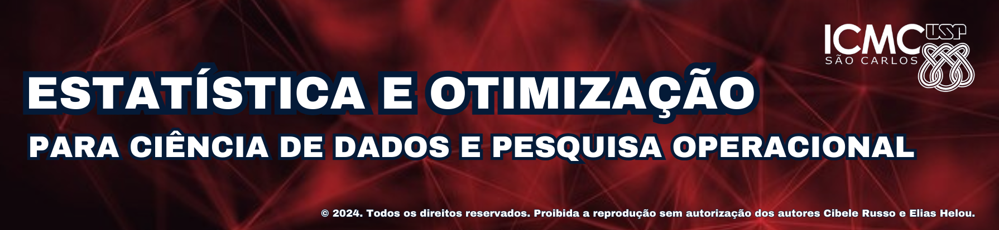

<h1 style = 'text-align: center;'>Algoritmos de Barreira</h1>

por **Elias Helou**

**ICMC/USP - São Carlos SP**

<h2>Conteúdo do Vídeo</h2>

1. Funções de Barreira

2. Algoritmos de Barreira

3. Exemplo

## 1. Funções de Barreira

### 1.1. Subproblemas Irrestritos

Uma ideia muito comum em otimização com restrições é substituir o problema original por uma sequência de problemas sem restrições.

O algoritmo terá a forma
$$\def\vect{\boldsymbol}
    \vect x^{( k )} = \argmin_{\vect x\in\mathbb R^n}\  f_k( \vect x ).
$$

Há diversas maneiras de gerar a sequência $\{ f_k \}$, dentre as quais

- métodos de barreira

- métodos de penalização

- métodos de lagrangiano aumentado

Neste vídeo, veremos métodos de barreira.

### 1.2. Pontos Interiores e a Condição de Slater

Considere um problema de otimização com restrições de desigualdade da forma
$$\def\vect{\boldsymbol}
    \begin{align*}
        \min       & \quad f( \vect x )\\
        \text{s.a:}& \quad g_i( \vect x ) \le 0 & i \in \{ 1, 2, \dots, p \}.
    \end{align*}
$$
<br><br>

Iremos supor que vale a *condição de Slater*, ou seja, existe $\vect x_s$ tal que
$$
    g_i( \vect x_s ) < 0 \qquad i \in \{ 1, 2, \dots, p \}.
$$

Um ponto como $\vect x_s$ é chamado de _ponto interior_.
<br><br><br>

Ou seja, a condição de Slater equivale a dizer que o conjunto viável possui um ponto interior.

### 1.3. Funções de Barreira

Uma função de barreira $B : \mathbb R \to \mathbb R$ é uma função univariada

- cujo valor cresce ilimitadamente quando $x < 0$ e $x \to 0$:
$$
    \lim_{x \uparrow 0} B( x ) = \infty
$$

- contínua para $x < 0$
<br><br>

Exemplos:

- barreira logarítmica
$$
    B( x ) = -\log( -x )
$$

- barreira inversa
$$
    B( x ) = -\frac1x
$$


In [1]:
import plotly
import plotly.graph_objects as go
import numpy as np
from IPython.display import display, HTML

plotly.offline.init_notebook_mode()
display(HTML(
    '<script type="text/javascript" async src="https://cdnjs.cloudflare.com/ajax/libs/mathjax/2.7.1/MathJax.js?config=TeX-MML-AM_SVG"></script>'
))


x_l = np.linspace( -5, -np.exp( -10 ), 200 )
y_l = -np.log( -x_l )
x_q = np.linspace( -5, -1e-1, 200 )
y_q = -1.0 / x_q

l_trace = go.Scatter(
    mode = 'lines',
    x = x_l,
    y = y_l,
    name = r'$-\log( -x )$',
    hoverinfo = 'skip',
    hovertemplate = None
)
q_trace = go.Scatter(
    mode = 'lines',
    x = x_q,
    y = y_q,
    name = r'$-1/x$',
    hoverinfo = 'skip',
    hovertemplate = None
)

fig = go.Figure(
    data = [ q_trace, l_trace ],
    layout = dict(
        title = 'Exemplos de Funções Barreira'
    )
)

fig.show()

## 2. Algoritmos de Barreira

Agora consideraremos algoritmos com a forma
$$\def\vect{\boldsymbol}
    \vect x^{( k )} = \argmin_{\vect x\in\mathbb R^n}\  f( \vect x ) + \rho_k\sum_{i = 1}^pB( g_i( \vect x ) ).
$$

Na formulação acima, $\{ \rho_k \} \subset \mathbb R_+$ é uma sequência de parâmetros de barreira que deve satisfazer
$$
    \rho_k \downarrow 0.
$$

Observe que

- as restrições $g_i( \vect x ) \le 0$ foram transferidas para a função objetivo

- os algoritmos devem gerar pontos no interior do conjunto viável

- a importância das funções barreira vai sendo reduzida

- o resultado da iteração anterior pode ser usado como ponto inicial do método da iteração atual


### 2.1. Minimizando o Problema Irrestrito

O primeiro passo é observar que
$$\def\vect{\boldsymbol}
    \nabla f_k( \vect x ) = \nabla f( \vect x ) + \rho_k \sum_{i = 1}^pB'( g_i( \vect x ) )\nabla g_i( \vect x ).
$$

Por exemplo

- barreira logarítmica
$$\def\vect{\boldsymbol}
    \nabla f_k( \vect x ) = \nabla f( \vect x ) + \rho_k \sum_{i = 1}^p\frac1{-g_i( \vect x )}\nabla g_i( \vect x ).
$$

- barreira inversa
$$\def\vect{\boldsymbol}
    \nabla f_k( \vect x ) = \nabla f( \vect x ) + \rho_k \sum_{i = 1}^p\frac1{g_i^2( \vect x )}\nabla g_i( \vect x ).
$$

Observe que

- o gradiente $\nabla g_i( \vect x )$ fica mais importante conforme $g_i( \vect x ) \uparrow 0$

- conforme $\rho_k \downarrow 0$, o método permite se aproximar da fronteira do conjunto viável

## 3. Exemplo

### 3.1. Modelo

Iremos resolver o seguinte exemplo
$$\def\vect{\boldsymbol}
    \begin{align*}
        \min       & \quad f( \vect x ) = 100( x_2 - x_1^2 )^2 + ( x_1 - 1 )^2\\
        \text{s.a:}& \quad g( \vect x ) = \| \vect x - \vect c \|_2^2 - r^2 \le 0.
    \end{align*}
$$


- a função objetivo é a função de Rosenbrock
$$\def\vect{\boldsymbol}
    f( \vect x ) = 100( x_2 - x_1^2 )^2 + ( x_1 - 1 )^2
$$
<div style="text-align: center;">
    <iframe type="text/html" src="https://en.wikipedia.org/wiki/Rosenbrock_function" width="90%" height="500" style="text-align: center; border: solid; border-radius: 10px"> 
</div>


- cujo gradiente é
$$
    \nabla f( \vect x ) = \begin{pmatrix}
                            -400( x_2 - x_1^2 ) x_1 + 2( x_1 - 1 )\\[1em]
                            200( x_2 - x_1^2 )
                          \end{pmatrix}
$$

- as implementações estão abaixo

In [2]:
def rosenbrock( x ):

    return 100 * ( x[ 1 ] - x[ 0 ] ** 2 ) ** 2 + ( x[ 0 ] - 1 ) ** 2

def rosenbrock_grad( x ):

    return np.array(
        (
            -400 * ( x[ 1 ] - x[ 0 ] ** 2 ) * x[ 0 ] + 2 * ( x[ 0 ] - 1 ),
             200 * ( x[ 1 ] - x[ 0 ] ** 2 )
        )
    )

- a restrição será estarmos dentro de um disco de raio $r$ centrado em $\def\vect{\boldsymbol}\vect c$
$$
  \begin{array}{rcrl}
      \| \vect x - \vect c \|_2 \le r & \Leftrightarrow & \sqrt{ ( x_1 - c_1 )^2 + ( x_2 - c_2 )^2 } & {}\le r\\[0.5em]
        & \Leftrightarrow & ( x_1 - c_1 )^2 + ( x_2 - c_2 )^2 & {}\le r^2\\[0.5em]
        & \Leftrightarrow & ( x_1 - c_1 )^2 + ( x_2 - c_2 )^2 - r^2 & {}\le 0
  \end{array}
$$

- ou $g( \vect x ) \le 0$ com
$$
  g( \vect x ) = ( x_1 - c_1 )^2 + ( x_2 - c_2 )^2 - r^2
$$

- portanto
$$
    \nabla g( \vect x ) = \begin{pmatrix}
                            2( x_1 - c_1 )\\[1em]
                            2( x_2 - c_2 )
                          \end{pmatrix}
$$

- usaremos
$$
  \vect c = ( -0.4, -0.4 )^T\qquad\text e\qquad r = 0.5
$$

- as implementações estão abaixo

In [3]:
r = 0.5
c_x = -0.4
c_y = -0.4

def g( x ):
    return ( c_x - x[ 0 ] ) ** 2 + ( c_y - x[ 1 ] ) ** 2 - r ** 2

def grad_g( x ):
    return np.array(
        [
            2 * ( x[ 0 ] - c_x ),
            2 * ( x[ 1 ] - c_y )
        ]
    )

- abaixo temos uma visualização do problema

In [4]:
x_min = -1.0
x_max =  1.0

n = 200

X = np.linspace( x_min, x_max, n )
z = np.empty( ( len( X ), len( X ) ) )
for j, x in enumerate( X ):
    for i, y in enumerate( X ):
        z[ i, j ] = rosenbrock( np.array( ( x, y ) ) )

img = go.Contour(
    x = X,
    y = X,
    z = z,
    ncontours = 100,
    line = { 'width': 0 },
    colorscale = 'gray_r',
    name = 'f( x, y )'
)

c_trace = go.Scatter(
    mode = 'lines',
    x = c_x + r * np.cos( np.linspace( 0, 2 * np.pi, n ) ),
    y = c_y + r * np.sin( np.linspace( 0, 2 * np.pi, n ) ),
    line = {
        'width': 1.5,
        'color': 'rgb( 255, 153, 28 )'
    },
    hoverinfo = 'skip',
    text = None,
    name = '',
    fill = 'toself'
 )

fig = go.Figure(
    data = [ img, c_trace ],
    layout = {
        'width'        : 550,
        'height'       : 550,
        'xaxis'        : dict(
            showgrid = False,
            zeroline = False,
            showticklabels = False,
            range = ( x_min, x_max )
            ),
        'yaxis'        : dict(
            showgrid = False,
            zeroline = False,
            showticklabels = False,
            range = ( x_min, x_max ),
            scaleanchor = 'x',
            scaleratio = 1.0
            ),
        'plot_bgcolor' : 'rgb( 255, 255, 255 )',
        'showlegend': False,
        'margin': dict( b = 0, l = 0, r = 0, t = 0 )
        }
)

fig.show()

### 3.2. O Algoritmo

- usaremos máxima descida com passo fixo no problema irrestrito

- o valor da função objetivo não é necessário nesse caso

- não precisamos precisão elevada no método irrestrito

- o valor das funções de restrição é necessário

- abaixo temos a implementação

In [5]:
def md( x, step, grad, niter ):

    for i in range( niter ):
        x = x - step * grad( x )
    
    return x

def barreira_log( x, f, grad_f, g, grad_g, step, niter = 100, niter_md = 100 ):

    iters = [ x ]

    for i in range( niter ):

        rho_k = 1.0e-1 / ( i + 1 )

        def f_k( x ):

            retval = 0.0
            for g_i in g:
                retval += np.log( -g_i( x ) )
            retval = f( x ) - rho_k * retval
        
            return retval

        def gradf_k( x ):

            retval = 0.0
            for ( g_i, grad_g_i ) in zip( g, grad_g ):
                retval += ( grad_g_i( x ) / g_i( x ) )
            retval = grad_f( x ) - rho_k * retval
        
            return retval
        
        x = md( x, step, gradf_k, niter_md )

        iters.append( x )

    return iters              

### 3.3. Execução

In [17]:
iters = barreira_log(
    np.array( [ c_x, c_y ] ),
    rosenbrock, rosenbrock_grad,
    [ g ], [ grad_g ],
    1.0e-4,
    niter_md = 100,
    niter = 100
)

print( iters[ -1 ] )
print( rosenbrock( iters[ -1 ] ) )
print( g( iters[ -1 ] ) )

[-0.08783276 -0.00971696]
1.2137660451903975
-0.0002307685388749925


In [18]:
x_min = -1.0
x_max =  1.0

n = 200

X = np.linspace( x_min, x_max, n )
z = np.empty( ( len( X ), len( X ) ) )
for j, x in enumerate( X ):
    for i, y in enumerate( X ):
        z[ i, j ] = rosenbrock( np.array( ( x, y ) ) )

img = go.Contour(
    x = X,
    y = X,
    z = z,
    ncontours = 100,
    line = { 'width': 0 },
    colorscale = 'gray_r',
    name = 'f( x, y )'
)

c_trace = go.Scatter(
    mode = 'lines',
    x = c_x + r * np.cos( np.linspace( 0, 2 * np.pi, n ) ),
    y = c_y + r * np.sin( np.linspace( 0, 2 * np.pi, n ) ),
    line = {
        'width': 1.5,
        'color': 'rgb( 255, 153, 28 )'
    },
    hoverinfo = 'skip',
    text = None,
    name = '',
    fill = 'toself'
 )

iters_trace = go.Scatter(
    x = [ x[ 0 ] for x in iters ],
    y = [ x[ 1 ] for x in iters ],
    mode = 'markers',
    hoverinfo = 'text'
)
it = []
for i, x in enumerate( iters ):
    txt  = f'  x<sup>({i})</sup>   = ({x[ 0 ]: .2},{x[ 1 ]: .2})<sup>T</sup><br>'
    txt += f'f(x<sup>({i})</sup>)  =  {rosenbrock( x ): }<br>'
    txt += f'g(x<sup>({i})</sup>)  =  {g( x ): .2e}'
    it.append( txt )
iters_trace.text = it


fig = go.Figure(
    data = [ img, c_trace, iters_trace ],
    layout = {
        'width'        : 550,
        'height'       : 550,
        'xaxis'        : dict(
            showgrid = False,
            zeroline = False,
            showticklabels = False,
            range = ( x_min, x_max )
            ),
        'yaxis'        : dict(
            showgrid = False,
            zeroline = False,
            showticklabels = False,
            range = ( x_min, x_max ),
            scaleanchor = 'x',
            scaleratio = 1.0
            ),
        'plot_bgcolor' : 'rgb( 255, 255, 255 )',
        'showlegend': False,
        'margin': dict( b = 0, l = 0, r = 0, t = 0 ),
        'hoverlabel': dict(
            font = dict(
                family = "Courier New, monospace",
                size = 12
                )
            )
        }
)

fig.show()

### 3.4. Observações

- a otimização irrestrita pode ser inexata
$$\def\vect{\boldsymbol}
    \vect x^{( k )} \approx \argmin_{\vect x\in\mathbb R^n}\  f_k( \vect x )
$$

- o tamanho de passo precisa ser escolhido com cuidado

- os parâmetros de barreira precisam ser escolhidos com cuidado

- o método leva um número grande de iterações pra convergir

- pode se tornar numericamente mal-condicionado

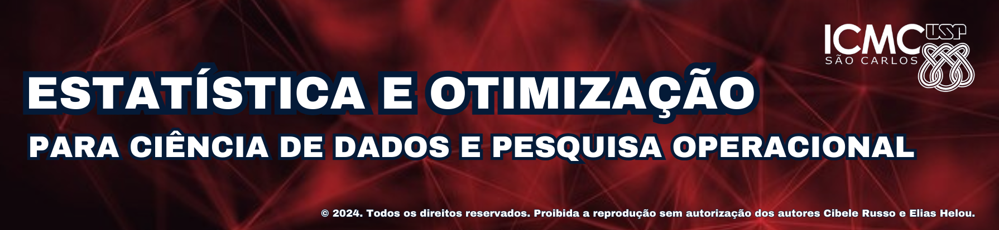

<h1 style = 'text-align: center;'>Algoritmos de Penalização</h1>

por **Elias Helou**

**ICMC/USP - São Carlos SP**

<h2>Conteúdo do Vídeo</h2>

1. Funções de Penalização

2. Algoritmos de Penalização

3. Exemplo

## 1. Funções de Penalização

### 1.1. Subproblemas Irrestritos

Retomamos a ideia de substituir o problema original restrito por uma sequência de problemas sem restrições.

O algoritmo terá a forma
$$\def\vect{\boldsymbol}
    \vect x^{( k )} = \argmin_{\vect x\in\mathbb R^n}\  f_k( \vect x ).
$$

Há diversas maneiras de gerar a sequência $\{ f_k \}$, dentre as quais

- métodos de barreira

- métodos de penalização

- métodos de lagrangiano aumentado

Neste vídeo, veremos métodos de penalização.

### 1.2. Funções de Penalização

Considere um problema de otimização com restrições de igualdade da forma
$$\def\vect{\boldsymbol}
    \begin{align*}
        \min       & \quad f( \vect x )\\
        \text{s.a:}& \quad h_j( \vect x ) = 0 & j \in \{ 1, 2, \dots, q \}.
    \end{align*}
$$
<br><br>

Uma função de penalização é uma função contínua $P : \mathbb R \to \mathbb R$ tal que

- $P( x )$ é estritamente crescente como função de $| x |$

- $P( 0 ) = 0$

Exemplos:

- $P( x ) = \frac12x^2$

- $P( x ) = | x |$

No nosso contexto, estas funções serão utilizadas para desestimular soluções que não satisfazem as restrições.


In [1]:
import plotly
import plotly.graph_objects as go
import numpy as np
from IPython.display import display, HTML

plotly.offline.init_notebook_mode()
display(HTML(
    '<script type="text/javascript" async src="https://cdnjs.cloudflare.com/ajax/libs/mathjax/2.7.1/MathJax.js?config=TeX-MML-AM_SVG"></script>'
))


x_m = np.linspace( -2.2, 2.2, 200 )
y_m = np.abs( x_m )
x_q = x_m
y_q = 0.5 * x_q ** 2

l_trace = go.Scatter(
    mode = 'lines',
    x = x_m,
    y = y_m,
    name = r'$| x |$',
    hoverinfo = 'skip',
    hovertemplate = None
)
q_trace = go.Scatter(
    mode = 'lines',
    x = x_q,
    y = y_q,
    name = r'$\frac12x^2$',
    hoverinfo = 'skip',
    hovertemplate = None
)

fig = go.Figure(
    data = [ q_trace, l_trace ],
    layout = dict(
        title = 'Exemplos de Funções de Penalização'
    )
)

fig.show()

## 2. Algoritmos de Penalização

Agora consideraremos algoritmos com a forma
$$\def\vect{\boldsymbol}
    \vect x^{( k )} = \argmin_{\vect x\in\mathbb R^n}\  f( \vect x ) + \rho_k\sum_{j = 1}^qP( h_j( \vect x ) ).
$$

Na formulação acima, $\{ \rho_k \} \subset \mathbb R_+$ é uma sequência de parâmetros de penalização que deve satisfazer
$$
    \rho_k \to \infty.
$$

Observe que

- as restrições $h_j( \vect x ) = 0$ foram transferidas para a função objetivo

- os algoritmos não geram pontos no interior do conjunto viável

- a importância das funções de penalização vai sendo aumentada

- o resultado da iteração anterior pode ser usado como ponto inicial do método da iteração atual

- em alguns casos há penalização exata, ou seja, não é necessário ter $\rho_k \to \infty$

### 2.1. Minimizando o Problema Irrestrito

O primeiro passo é observar que
$$\def\vect{\boldsymbol}
    \nabla f_k( \vect x ) = \nabla f( \vect x ) + \rho_k \sum_{j = 1}^qP'( h_j( \vect x ) )\nabla h_j( \vect x ).
$$

Por exemplo

- $P( x ) = \frac12x^2$
$$\def\vect{\boldsymbol}
    \nabla f_k( \vect x ) = \nabla f( \vect x ) + \rho_k \sum_{j = 1}^qh_j( \vect x )\nabla h_j( \vect x ).
$$

-  $P( x ) = | x |$ não é diferenciável

Observe que

- o gradiente $\nabla h_j( \vect x )$ fica menos importante conforme $h_j( \vect x ) \to 0$

- conforme $\rho_k \to \infty$, o método é obrigado a se aproximar do conjunto viável

- $P( x ) = | x |$ pode resultar em penalização exata, mas não é diferenciável

## 3. Exemplo

### 3.1. Modelo

Iremos resolver o seguinte exemplo
$$\def\vect{\boldsymbol}
    \begin{align*}
        \min       & \quad f( \vect x ) = 100( x_2 - x_1^2 )^2 + ( x_1 - 1 )^2\\
        \text{s.a:}& \quad g( \vect x ) = \| \vect x - \vect c \|_2^2 - r^2 \le 0.
    \end{align*}
$$


- a função objetivo é a função de Rosenbrock
$$\def\vect{\boldsymbol}
    f( \vect x ) = 100( x_2 - x_1^2 )^2 + ( x_1 - 1 )^2
$$
<div style="text-align: center;">
    <iframe type="text/html" src="https://en.wikipedia.org/wiki/Rosenbrock_function" width="90%" height="500" style="text-align: center; border: solid; border-radius: 10px"> 
</div>


- cujo gradiente é
$$
    \nabla f( \vect x ) = \begin{pmatrix}
                            -400( x_2 - x_1^2 ) x_1 + 2( x_1 - 1 )\\[1em]
                            200( x_2 - x_1^2 )
                          \end{pmatrix}
$$

- as implementações estão abaixo

In [2]:
def rosenbrock( x ):

    return 100 * ( x[ 1 ] - x[ 0 ] ** 2 ) ** 2 + ( x[ 0 ] - 1 ) ** 2

def rosenbrock_grad( x ):

    return np.array(
        (
            -400 * ( x[ 1 ] - x[ 0 ] ** 2 ) * x[ 0 ] + 2 * ( x[ 0 ] - 1 ),
             200 * ( x[ 1 ] - x[ 0 ] ** 2 )
        )
    )

- a restrição será estarmos dentro de um disco de raio $r$ centrado em $\def\vect{\boldsymbol}\vect c$
$$
  \begin{array}{rcrl}
      \| \vect x - \vect c \|_2 \le r & \Leftrightarrow & \sqrt{ ( x_1 - c_1 )^2 + ( x_2 - c_2 )^2 } & {}\le r\\[0.5em]
        & \Leftrightarrow & ( x_1 - c_1 )^2 + ( x_2 - c_2 )^2 & {}\le r^2\\[0.5em]
        & \Leftrightarrow & ( x_1 - c_1 )^2 + ( x_2 - c_2 )^2 - r^2 & {}\le 0
  \end{array}
$$

- ou $g( \vect x ) \le 0$ com
$$
  g( \vect x ) = ( x_1 - c_1 )^2 + ( x_2 - c_2 )^2 - r^2
$$

- portanto
$$
    \nabla g( \vect x ) = \begin{pmatrix}
                            2( x_1 - c_1 )\\[1em]
                            2( x_2 - c_2 )
                          \end{pmatrix}
$$

- usaremos
$$
  \vect c = ( -0.4, -0.4 )^T\qquad\text e\qquad r = 0.5
$$

- note que nosso problema tem restrição de desigualdade, mas é possível transformar em desigualdade facilmente
$$\def\vect{\boldsymbol}
    g( \vect x ) \le 0 \Leftrightarrow \max\{ 0, g( \vect x ) \} = 0
$$

- veja que $h( \vect x ) = \max\{ 0, g( \vect x ) \}$ pode não ser diferenciável, mas $P( h( \vect x ) ) = \frac12h^2( \vect x )$ é continuamente diferenciável
$$
    \begin{align*}
        \frac{\mathrm d}{\mathrm dx} \max\{ 0, g( \vect x ) \}^2 & {}=
            \begin{cases}
                2g( \vect x )\nabla g( \vect x ) & g( \vect x ) > 0\\
                0 & g( \vect x ) \le 0
            \end{cases}\\
            & {}= 2h( \vect x )\nabla h( \vect x )
    \end{align*}
$$

In [3]:
x_m = np.linspace( -1, 1, 201 )
y_m = x_m.copy()
y_m[ y_m <= 0 ] = 0
y_q = y_m ** 2

l_trace = go.Scatter(
    mode = 'lines',
    x = x_m,
    y = y_m,
    name = r'$\max\{ 0, x \}$',
    hoverinfo = 'skip',
    hovertemplate = None
)
q_trace = go.Scatter(
    mode = 'lines',
    x = x_m,
    y = y_q,
    name = r'$\max\{ 0, x \}^2$',
    hoverinfo = 'skip',
    hovertemplate = None
)

fig = go.Figure(
    data = [ q_trace, l_trace ]
)

fig.show()

- as implementações estão abaixo

In [4]:
r = 0.5
c_x = -0.4
c_y = -0.4

def h( x ):
    retval = ( c_x - x[ 0 ] ) ** 2 + ( c_y - x[ 1 ] ) ** 2 - r ** 2
    return retval if retval >= 0 else 0.0

def grad_h( x ):
    return np.array(
        [
            2 * ( x[ 0 ] - c_x ),
            2 * ( x[ 1 ] - c_y )
        ]
    ) if ( c_x - x[ 0 ] ) ** 2 + ( c_y - x[ 1 ] ) ** 2 - r ** 2 >= 0 else \
    np.zeros( ( 2, ) )

- abaixo temos uma visualização do problema

In [5]:
x_min = -1.0
x_max =  1.0

n = 200

X = np.linspace( x_min, x_max, n )
z = np.empty( ( len( X ), len( X ) ) )
for j, x in enumerate( X ):
    for i, y in enumerate( X ):
        z[ i, j ] = rosenbrock( np.array( ( x, y ) ) )

img = go.Contour(
    x = X,
    y = X,
    z = z,
    ncontours = 100,
    line = { 'width': 0 },
    colorscale = 'gray_r',
    name = 'f( x, y )'
)

c_trace = go.Scatter(
    mode = 'lines',
    x = c_x + r * np.cos( np.linspace( 0, 2 * np.pi, n ) ),
    y = c_y + r * np.sin( np.linspace( 0, 2 * np.pi, n ) ),
    line = {
        'width': 1.5,
        'color': 'rgb( 255, 153, 28 )'
    },
    hoverinfo = 'skip',
    text = None,
    name = '',
    fill = 'toself'
 )

fig = go.Figure(
    data = [ img, c_trace ],
    layout = {
        'width'        : 550,
        'height'       : 550,
        'xaxis'        : dict(
            showgrid = False,
            zeroline = False,
            showticklabels = False,
            range = ( x_min, x_max )
            ),
        'yaxis'        : dict(
            showgrid = False,
            zeroline = False,
            showticklabels = False,
            range = ( x_min, x_max ),
            scaleanchor = 'x',
            scaleratio = 1.0
            ),
        'plot_bgcolor' : 'rgb( 255, 255, 255 )',
        'showlegend': False,
        'margin': dict( b = 0, l = 0, r = 0, t = 0 )
        }
)

fig.show()

### 3.2. O Algoritmo

- usaremos máxima descida com passo fixo no problema irrestrito

- o valor da função objetivo não é necessário nesse caso

- o valor das funções de restrição é necessário

- abaixo temos a implementação

In [6]:
def md( x, step, grad, niter ):

    for i in range( niter ):
        x = x - step * grad( x )
    
    return x

def penalizacao( x, f, grad_f, h, grad_h, step, niter = 100, niter_md = 100  ):

    iters = [ x ]

    for i in range( niter ):

        rho_k = 1.0e2 * i

        def f_k( x ):
            retval = f( x )
            for h_i in h:
                retval += 0.5 * rho_k * ( h_i( x ) ** 2 )
 
            return retval
 
        def gradf_k( x ):

            retval = 0.0
            for ( h_i, grad_h_i ) in zip( h, grad_h ):
                retval += ( h_i( x ) * grad_h_i( x ) )
            retval = grad_f( x ) + rho_k * retval
        
            return retval
        
        x = md( x, step, gradf_k, niter_md )
        iters.append( x )
        
    return iters


### 3.3. Execução

In [10]:
iters = penalizacao(
    np.array( [ c_x, c_y ] ),
    rosenbrock, rosenbrock_grad,
    [ h ], [ grad_h ],
    1.0e-4,
    niter_md = 10,
    niter = 100
)

In [11]:
print( iters[ -1 ] )
print( rosenbrock( iters[ -1 ] ) )
print( h( iters[ -1 ] ) )

[-0.0870669  -0.00946697]
1.2107765858594863
0.0004431673963156135


In [12]:
x_min = -1.0
x_max =  1.0

n = 200

X = np.linspace( x_min, x_max, n )
z = np.empty( ( len( X ), len( X ) ) )
for j, x in enumerate( X ):
    for i, y in enumerate( X ):
        z[ i, j ] = rosenbrock( np.array( ( x, y ) ) )

img = go.Contour(
    x = X,
    y = X,
    z = z,
    ncontours = 100,
    line = { 'width': 0 },
    colorscale = 'gray_r',
    name = 'f( x, y )'
)

c_trace = go.Scatter(
    mode = 'lines',
    x = c_x + r * np.cos( np.linspace( 0, 2 * np.pi, n ) ),
    y = c_y + r * np.sin( np.linspace( 0, 2 * np.pi, n ) ),
    line = {
        'width': 1.5,
        'color': 'rgb( 255, 153, 28 )'
    },
    hoverinfo = 'skip',
    text = None,
    name = '',
    fill = 'toself'
 )

iters_trace = go.Scatter(
    x = [ x[ 0 ] for x in iters ],
    y = [ x[ 1 ] for x in iters ],
    mode = 'markers',
    hoverinfo = 'text'
)
it = []
for i, x in enumerate( iters ):
    txt  = f'  x<sup>({i})</sup>   = ({x[ 0 ]: .2},{x[ 1 ]: .2})<sup>T</sup><br>'
    txt += f'f(x<sup>({i})</sup>)  =  {rosenbrock( x ): }<br>'
    txt += f'h(x<sup>({i})</sup>)  =  {h( x ): .2e}'
    it.append( txt )
iters_trace.text = it

last_trace = go.Scatter(
    x = [ iters[ -1 ][ 0 ] ],
    y = [ iters[ -1 ][ 1 ] ],
    mode = 'markers',
    hoverinfo = 'skip',
    marker = { 'color': 'red' }
)

fig = go.Figure(
    data = [ img, c_trace, iters_trace, last_trace ],
    layout = {
        'width'        : 550,
        'height'       : 550,
        'xaxis'        : dict(
            showgrid = False,
            zeroline = False,
            showticklabels = False,
            range = ( x_min, x_max )
            ),
        'yaxis'        : dict(
            showgrid = False,
            zeroline = False,
            showticklabels = False,
            range = ( x_min, x_max ),
            scaleanchor = 'x',
            scaleratio = 1.0
            ),
        'plot_bgcolor' : 'rgb( 255, 255, 255 )',
        'showlegend': False,
        'margin': dict( b = 0, l = 0, r = 0, t = 0 ),
        'hoverlabel': dict(
            font = dict(
                family = "Courier New, monospace",
                size = 12
                )
            )
        }
)

fig.show()

### 3.4. Observações

- a otimização irrestrita pode ser inexata
$$\def\vect{\boldsymbol}
    \vect x^{( k )} \approx \argmin_{\vect x\in\mathbb R^n}\  f_k( \vect x )
$$

- o tamanho de passo pode ser escolhido com menos cuidado (mas influencia a eficiência)

- os parâmetros de penalização podem ser escolhidos com menos cuidado (mas influenciam a eficiência)

- o método leva um número grande de iterações pra convergir

- pode se tornar numericamente mal-condicionado

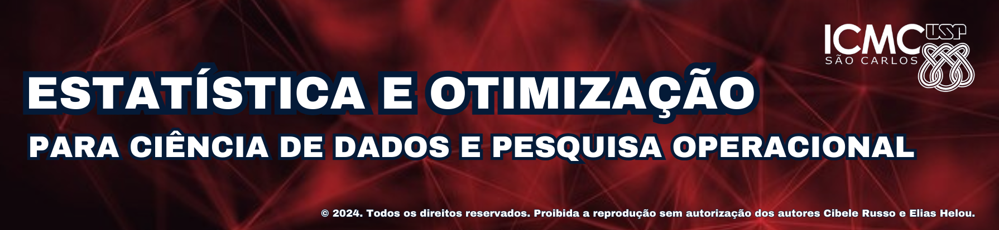

<h1 style = 'text-align: center;'>Algoritmos de Lagrangiano Aumentado</h1>

por **Elias Helou**

**ICMC/USP - São Carlos SP**

<h2>Conteúdo do Vídeo</h2>

1. Condições de Karush-Kuhn-Tucker

2. Algoritmos de Lagrangiano Aumentado

3. Exemplo

## 1. Condições de Karush-Kuhn-Tucker

### 1.1. O Caso Irrestrito

Para o problema
$$\def\vect{\boldsymbol}
    \min f( \vect x ),
$$
sabemos que
$$\def\vect{\boldsymbol}
    \nabla f( \vect x^* ) = \vect 0
$$
é condição necessária para $\vect x^*$ ser um minimizador.

### 1.2. O Caso com Restrições

E para o problema abaixo
$$\def\vect{\boldsymbol}
    \begin{align*}
        \min       & \quad f( \vect x )\\
        \text{s.a:}& \quad g_i( \vect x ) \le 0 & i \in \{ 1, 2, \dots, p \}\phantom?\\
                   & \quad h_j( \vect x ) = 0   & j\in \{ 1, 2, \dots, q \}?
    \end{align*}
$$

A resposta é que as condições de Karush-Kuhn-Tucker (KKT) devem valer:
$$\def\vect{\boldsymbol}
    \begin{align}
        \nabla f( \vect x^* ) + \sum_{i = 1}^p \mu_i^*\nabla g_i( \vect x^* ) + \sum_{j = 1}^q \lambda_j^*\nabla h_j( \vect x^* ) & {} = \vect 0\\
        g_i( \vect x^* ) & {}\le 0 & i \in \{ 1, 2, \dots, p \}\\
        h_j( \vect x^* ) & {}= 0 & j \in \{ 1, 2, \dots, q \}\\
        \mu_i^* & {} \ge 0 & i \in \{ 1, 2, \dots, p \}\\
        \mu_i^*g_i( \vect x^* ) & {} = 0 & i \in \{ 1, 2, \dots, p \}
    \end{align}
$$

- (1) estacionariedade

- (2) e (3) viabilidade primal

- (4) viabilidade dual

- (5) folga complementar

**Observação:** as condições KKT são necessárias quando valem determinadas condições de qualificação das restrições (não basta diferenciabilidade)
<div style="text-align: center;">
    <iframe type="text/html" src="https://en.wikipedia.org/wiki/Karush%E2%80%93Kuhn%E2%80%93Tucker_conditions" width="90%" height="500" style="text-align: center; border: solid; border-radius: 10px"> 
</div>

### 1.3. Restrições de Igualdade

Para o problema
$$\def\vect{\boldsymbol}
    \begin{align*}
        \min       & \quad f( \vect x )\\
        \text{s.a:}& \quad h_j( \vect x ) = 0   & j\in \{ 1, 2, \dots, q \}
    \end{align*}
$$
as condições KKT simplificam-se para
$$\def\vect{\boldsymbol}
    \begin{align*}
        \nabla f( \vect x^* ) + \sum_{j = 1}^q \lambda_j^*\nabla h_j( \vect x^* ) & {} = \vect 0\\
        h_j( \vect x^* ) & {}= 0 & j \in \{ 1, 2, \dots, q \}.
    \end{align*}
$$


## 2. Métodos de Lagrangiano Aumentado

### 2.1. Função Lagrangiana

- considere a função lagrangiana
$$\def\vect{\boldsymbol}
    L( \vect x, \vect \lambda ) = f( \vect x ) + \vect\lambda^T\vect h( \vect x )
$$

- então a estacionariedade implica que
$$
    \nabla_{\vect x} L( \vect x^*, \vect \lambda^* ) = \vect 0.
$$

### 2.2. Função Lagrangiana Aumentada

- considere a função lagrangiana aumentada
$$\def\vect{\boldsymbol}
    L^\rho( \vect x, \vect \lambda ) = f( \vect x ) + \vect\lambda^T\vect h( \vect x ) + \frac\rho2\| \vect h( \vect x ) \|_2^2
$$

- então a estacionariedade mais a viabilidade implicam que
$$
\begin{align*}
    \nabla_{\vect x} L^\rho( \vect x^*, \vect \lambda^* ) &{}= \nabla f( \vect x^* ) + \sum_{j = 1}^q\lambda_j^*\nabla h_j( \vect x^* ) + \rho\sum_{j = 1}^q h_j( \vect x^* )\nabla h_j( \vect x^* )\\
        & {}= \vect 0.
\end{align*}
$$

- se conhecêssemos $\vect\lambda^*$, bastaria minimizar $L^\rho$

### 2.3. Algoritmo

$$\def\vect{\boldsymbol}
\begin{align*}
    \vect x^{( k )} & {}= \argmin_{\vect x\in \mathbb R^n}\ L^{\rho_k}( \vect x, \vect \lambda^{( k )} )\\[1.5em]
    \vect\lambda^{( k + 1 )} & {}= \vect\lambda^{( k )} + \rho_k\vect h( \vect x^{( k )} )\\
        & {}= \vect\lambda^{( k )} +\rho_k\nabla_{\vect \lambda} L^{\rho_k}( \vect x^{( k )}, \vect \lambda^{( k )} )
\end{align*}
$$

- atualização primal

- atualização dual

- não precisamos de $\rho_k \to \infty$

## 3. Exemplo

### 3.1. Modelo

Iremos resolver o seguinte exemplo
$$\def\vect{\boldsymbol}
    \begin{align*}
        \min       & \quad f( \vect x ) = 100( x_2 - x_1^2 )^2 + ( x_1 - 1 )^2\\
        \text{s.a:}& \quad g( \vect x ) = \| \vect x - \vect c \|_2^2 - r^2 \le 0.
    \end{align*}
$$


- a função objetivo é a função de Rosenbrock
$$\def\vect{\boldsymbol}
    f( \vect x ) = 100( x_2 - x_1^2 )^2 + ( x_1 - 1 )^2
$$
<div style="text-align: center;">
    <iframe type="text/html" src="https://en.wikipedia.org/wiki/Rosenbrock_function" width="90%" height="500" style="text-align: center; border: solid; border-radius: 10px"> 
</div>


- cujo gradiente é
$$
    \nabla f( \vect x ) = \begin{pmatrix}
                            -400( x_2 - x_1^2 ) x_1 + 2( x_1 - 1 )\\[1em]
                            200( x_2 - x_1^2 )
                          \end{pmatrix}
$$

- as implementações estão abaixo

In [1]:
import numpy as np

def rosenbrock( x ):

    return 100 * ( x[ 1 ] - x[ 0 ] ** 2 ) ** 2 + ( x[ 0 ] - 1 ) ** 2

def rosenbrock_grad( x ):

    return np.array(
        (
            -400 * ( x[ 1 ] - x[ 0 ] ** 2 ) * x[ 0 ] + 2 * ( x[ 0 ] - 1 ),
             200 * ( x[ 1 ] - x[ 0 ] ** 2 )
        )
    )

- a restrição será estarmos dentro de um disco de raio $r$ centrado em $\def\vect{\boldsymbol}\vect c$
$$
  \begin{array}{rcrl}
      \| \vect x - \vect c \|_2 \le r & \Leftrightarrow & \sqrt{ ( x_1 - c_1 )^2 + ( x_2 - c_2 )^2 } & {}\le r\\[0.5em]
        & \Leftrightarrow & ( x_1 - c_1 )^2 + ( x_2 - c_2 )^2 & {}\le r^2\\[0.5em]
        & \Leftrightarrow & ( x_1 - c_1 )^2 + ( x_2 - c_2 )^2 - r^2 & {}\le 0
  \end{array}
$$

- ou $g( \vect x ) \le 0$ com
$$
  g( \vect x ) = ( x_1 - c_1 )^2 + ( x_2 - c_2 )^2 - r^2
$$

- portanto
$$
    \nabla g( \vect x ) = \begin{pmatrix}
                            2( x_1 - c_1 )\\[1em]
                            2( x_2 - c_2 )
                          \end{pmatrix}
$$

- usaremos
$$
  \vect c = ( -0.4, -0.4 )^T\qquad\text e\qquad r = 0.5
$$

- note que nosso problema tem restrição de desigualdade, mas é possível transformar em desigualdade facilmente
$$\def\vect{\boldsymbol}
    g( \vect x ) \le 0 \Leftrightarrow \max\{ 0, g( \vect x ) \} = 0
$$

- veja que $h( \vect x ) = \max\{ 0, g( \vect x ) \}$ pode não ser diferenciável, mas $P( h( \vect x ) ) = \frac12h^2( \vect x )$ é continuamente diferenciável
$$
    \begin{align*}
        \frac{\mathrm d}{\mathrm dx} \max\{ 0, g( \vect x ) \}^2 & {}=
            \begin{cases}
                2g( \vect x )\nabla g( \vect x ) & g( \vect x ) > 0\\
                0 & g( \vect x ) \le 0
            \end{cases}\\
            & {}= 2h( \vect x )\nabla h( \vect x )
    \end{align*}
$$

- as implementações estão abaixo

In [2]:
r = 0.5
c_x = -0.4
c_y = -0.4

def h( x ):
    retval = ( c_x - x[ 0 ] ) ** 2 + ( c_y - x[ 1 ] ) ** 2 - r ** 2
    return retval if retval >= 0 else 0.0

def grad_h( x ):
    return np.array(
        [
            2 * ( x[ 0 ] - c_x ),
            2 * ( x[ 1 ] - c_y )
        ]
    ) if ( c_x - x[ 0 ] ) ** 2 + ( c_y - x[ 1 ] ) ** 2 - r ** 2 >= 0 else \
    np.zeros( ( 2, ) )

- abaixo temos uma visualização do problema

In [3]:
import plotly.graph_objects as go

x_min = -1.0
x_max =  1.0

n = 200

X = np.linspace( x_min, x_max, n )
z = np.empty( ( len( X ), len( X ) ) )
for j, x in enumerate( X ):
    for i, y in enumerate( X ):
        z[ i, j ] = rosenbrock( np.array( ( x, y ) ) )

img = go.Contour(
    x = X,
    y = X,
    z = z,
    ncontours = 100,
    line = { 'width': 0 },
    colorscale = 'gray_r',
    name = 'f( x, y )'
)

c_trace = go.Scatter(
    mode = 'lines',
    x = c_x + r * np.cos( np.linspace( 0, 2 * np.pi, n ) ),
    y = c_y + r * np.sin( np.linspace( 0, 2 * np.pi, n ) ),
    line = {
        'width': 1.5,
        'color': 'rgb( 255, 153, 28 )'
    },
    hoverinfo = 'skip',
    text = None,
    name = '',
    fill = 'toself'
 )

fig = go.Figure(
    data = [ img, c_trace ],
    layout = {
        'width'        : 550,
        'height'       : 550,
        'xaxis'        : dict(
            showgrid = False,
            zeroline = False,
            showticklabels = False,
            range = ( x_min, x_max )
            ),
        'yaxis'        : dict(
            showgrid = False,
            zeroline = False,
            showticklabels = False,
            range = ( x_min, x_max ),
            scaleanchor = 'x',
            scaleratio = 1.0
            ),
        'plot_bgcolor' : 'rgb( 255, 255, 255 )',
        'showlegend': False,
        'margin': dict( b = 0, l = 0, r = 0, t = 0 )
        }
)

fig.show()

### 3.2. O Algoritmo

- usaremos máxima descida com passo fixo no problema irrestrito

- o valor da função objetivo não é necessário nesse caso

- o valor das funções de restrição é necessário

- abaixo temos a implementação

In [4]:
def md( x, step, grad, niter ):

    for i in range( niter ):
        x = x - step * grad( x )
    
    return x

def lagrangiano(
        x,
        f, grad_f,
        h, grad_h,
        step, rho,
        niter = 100, niter_md = 100,
        lbd = None
):

    if lbd is None:
        lbd = np.zeros( len( h ) )

    iters = [ ( x, lbd ) ]

    for i in range( niter ):

        def f_k( x ):
            retval = f( x )
            for h_i in h:
                retval += 0.5 * rho * ( h_i( x ) ** 2 )
 
            return retval
 
        def gradf_k( x ):

            retval = 0.0
            for ( h_i, grad_h_i, lbd_i ) in zip( h, grad_h, lbd ):
                retval += ( ( lbd_i + rho * h_i( x ) ) * grad_h_i( x ) )
            retval = grad_f( x ) +  retval
        
            return retval
        
        x = md( x, step, gradf_k, niter_md )
        for i, h_i in enumerate( h ):
            lbd[ i ] += rho * h_i( x )

        iters.append( ( x, lbd ) )
        
    return iters


### 3.3. Execução

In [5]:
iters_lbd = lagrangiano(
    np.array( [ c_x, c_y ] ),
    rosenbrock, rosenbrock_grad,
    [ h ], [ grad_h ],
    1.0e-4, 1.0e2,
    niter_md = 100,
    niter = 100
)

In [6]:
iters = [ i[ 0 ] for i in iters_lbd ]
lbds = [ i[ 1 ] for i in iters_lbd ]

print( iters[ -1 ], lbds[ -1 ] )
print( rosenbrock( iters[ -1 ] ) )
print( h( iters[ -1 ] ) )

[-0.08731467 -0.00984862] [6.12716261]
1.2127819398575423
0.0


In [7]:
x_min = -1.0
x_max =  1.0

n = 200

X = np.linspace( x_min, x_max, n )
z = np.empty( ( len( X ), len( X ) ) )
for j, x in enumerate( X ):
    for i, y in enumerate( X ):
        z[ i, j ] = rosenbrock( np.array( ( x, y ) ) )

img = go.Contour(
    x = X,
    y = X,
    z = z,
    ncontours = 100,
    line = { 'width': 0 },
    colorscale = 'gray_r',
    name = 'f( x, y )'
)

c_trace = go.Scatter(
    mode = 'lines',
    x = c_x + r * np.cos( np.linspace( 0, 2 * np.pi, n ) ),
    y = c_y + r * np.sin( np.linspace( 0, 2 * np.pi, n ) ),
    line = {
        'width': 1.5,
        'color': 'rgb( 255, 153, 28 )'
    },
    hoverinfo = 'skip',
    text = None,
    name = '',
    fill = 'toself'
 )

iters_trace = go.Scatter(
    x = [ x[ 0 ] for x in iters ],
    y = [ x[ 1 ] for x in iters ],
    mode = 'markers',
    hoverinfo = 'text'
)
it = []
for i, x in enumerate( iters ):
    txt  = f'  x<sup>({i})</sup>   = ({x[ 0 ]: .2},{x[ 1 ]: .2})<sup>T</sup><br>'
    txt += f'f(x<sup>({i})</sup>)  =  {rosenbrock( x ): }<br>'
    txt += f'h(x<sup>({i})</sup>)  =  {h( x ): .2e}'
    it.append( txt )
iters_trace.text = it

last_trace = go.Scatter(
    x = [ iters[ -1 ][ 0 ] ],
    y = [ iters[ -1 ][ 1 ] ],
    mode = 'markers',
    hoverinfo = 'skip',
    marker = { 'color': 'red' }
)

fig = go.Figure(
    data = [ img, c_trace, iters_trace, last_trace ],
    layout = {
        'width'        : 550,
        'height'       : 550,
        'xaxis'        : dict(
            showgrid = False,
            zeroline = False,
            showticklabels = False,
            range = ( x_min, x_max )
            ),
        'yaxis'        : dict(
            showgrid = False,
            zeroline = False,
            showticklabels = False,
            range = ( x_min, x_max ),
            scaleanchor = 'x',
            scaleratio = 1.0
            ),
        'plot_bgcolor' : 'rgb( 255, 255, 255 )',
        'showlegend': False,
        'margin': dict( b = 0, l = 0, r = 0, t = 0 ),
        'hoverlabel': dict(
            font = dict(
                family = "Courier New, monospace",
                size = 12
                )
            )
        }
)

fig.show()

### 3.4. Observações

- a otimização irrestrita pode ser inexata
$$\def\vect{\boldsymbol}
    \vect x^{( k )} \approx \argmin_{\vect x\in \mathbb R^n}\ L^{\rho_k}( \vect x, \vect \lambda^{( k )} )
$$

- o parâmetro de penalização pode ser constante

- não se torna numericamente mal-condicionado

- o método não leva um número grande de iterações pra convergir
